# 04 — Model Ensembling: Combining 2D CNN & MLP

This notebook implements the **Ensemble Strategy** combining our two Deep Learning models:
1. **MLP (Deep Learning 1)**: Trained on 156 summary acoustic features per window (MFCCs, spectral moments, energy).
2. **2D CNN (Deep Learning 2)**: Trained on Log-Mel spectrograms (64 Mel bins $\times$ 312 time frames) capturing local 2D time-frequency murmur turbulence.

### Ensembling Rationale (Late Probability Blending)
Because the MLP and CNN process radically different representations of the audio signal (statistical window summaries vs. raw 2D spectrogram textures), their error distributions are largely complementary.

For each patient $p$, we compute a convex combination of class posterior probabilities:
$$\hat{P}_{\text{ens}}(p) = w \cdot \hat{P}_{\text{CNN}}(p) + (1 - w) \cdot \hat{P}_{\text{MLP}}(p), \quad w \in [0, 1]$$

We perform a grid sweep over $w$ to find the optimal weighting under the official **PhysioNet 5-Fold Cross-Validation Weighted Accuracy (WA)**.

In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.metrics import CLASSES, weighted_accuracy, report
from src.features import load_features
from src.mlp import DEFAULT_CFG as MLP_CFG, cross_validate as cv_mlp, patient_scores, predict_rule, tune_thresholds
from src.cnn import load_cnn_dataset

np.random.seed(42)
print('Libraries imported successfully.')

Libraries imported successfully.


## 1. Obtain Patient Scores for MLP (Deep Learning 1)

We run fast 5-fold CV for the MLP (~5 seconds) and aggregate window probabilities to patient level.

In [2]:
# Load tabular features and run fast 5-fold CV for MLP
meta_mlp, tabular_feats = load_features()
print(f"Loaded {len(meta_mlp)} windows with {len(tabular_feats)} tabular features.")

print("Training 5-fold CV for MLP...")
dev_mlp, oof_mlp, mlp_runs = cv_mlp(meta_mlp, tabular_feats, MLP_CFG)

# Aggregate window probabilities to patient level
pat_mlp = patient_scores(dev_mlp, oof_mlp)
pat_mlp['fold'] = dev_mlp.groupby('patient_id')['fold'].first()
print(f"Computed MLP patient scores for {len(pat_mlp)} patients.")

Loaded 24198 windows with 156 tabular features.
Training 5-fold CV for MLP...
fold 0: best epoch 0, val loss 0.930, window acc 0.497
fold 1: best epoch 0, val loss 0.878, window acc 0.519
fold 2: best epoch 2, val loss 0.979, window acc 0.522
fold 3: best epoch 2, val loss 0.855, window acc 0.578
fold 4: best epoch 0, val loss 0.901, window acc 0.496
Computed MLP patient scores for 753 patients.


## 2. Obtain Patient Scores for 2D CNN (Deep Learning 2)

We load the out-of-fold CNN predictions saved from `notebooks/03_cnn.ipynb`.

In [3]:
cnn_path = "../data/features/cnn_oof_probs.npy"
if not os.path.exists(cnn_path):
    raise FileNotFoundError(
        f"Could not find '{cnn_path}'. Please run the last cell of notebooks/03_cnn.ipynb to save the CNN predictions!"
    )

oof_cnn = np.load(cnn_path)
meta_cnn, _ = load_cnn_dataset()
dev_cnn = meta_cnn[meta_cnn['fold'] >= 0].reset_index(drop=True)

pat_cnn = patient_scores(dev_cnn, oof_cnn)
pat_cnn['fold'] = dev_cnn.groupby('patient_id')['fold'].first()
print(f"Loaded CNN patient scores for {len(pat_cnn)} patients.")

# Verify patient alignment
common_patients = sorted(list(set(pat_mlp.index).intersection(set(pat_cnn.index))))
pat_mlp = pat_mlp.loc[common_patients].copy()
pat_cnn = pat_cnn.loc[common_patients].copy()
assert (pat_mlp['fold'] == pat_cnn['fold']).all(), "Fold assignments must match!"
assert (pat_mlp['murmur'] == pat_cnn['murmur']).all(), "True murmur labels must match!"
print(f"Successfully aligned {len(common_patients)} patients across both models.")

Loaded CNN patient scores for 753 patients.
Successfully aligned 753 patients across both models.


## 3. Grid Search: Finding the Optimal Blending Weight $w$

We evaluate $w \in [0.0, 1.0]$ in increments of 0.05.
For each candidate weight:
1. Blend patient probabilities: $P = w \cdot P_{\text{CNN}} + (1 - w) \cdot P_{\text{MLP}}$
2. Tune decision thresholds $(t_{\text{present}}, t_{\text{unknown}})$ via 5-fold CV
3. Compute the official PhysioNet Weighted Accuracy (WA)

In [4]:
def eval_blend(w, pat_cnn, pat_mlp):
    """Evaluate blended probabilities for a given CNN weight w across 5-fold CV."""
    pat_blend = pat_cnn.copy()
    pat_blend['p_present'] = w * pat_cnn['p_present'] + (1.0 - w) * pat_mlp['p_present']
    pat_blend['p_unknown'] = w * pat_cnn['p_unknown'] + (1.0 - w) * pat_mlp['p_unknown']
    pat_blend['p_absent']  = w * pat_cnn['p_absent']  + (1.0 - w) * pat_mlp['p_absent']
    
    fold_was = []
    pred_series = pd.Series(index=pat_blend.index, dtype=object)
    
    for k in sorted(pat_blend['fold'].unique()):
        val = pat_blend[pat_blend['fold'] == k]
        train_folds = pat_blend[pat_blend['fold'] != k]
        
        t_opt, _ = tune_thresholds(train_folds)
        pred_val = predict_rule(val, *t_opt)
        pred_series[val.index] = pred_val
        
        wa_k = weighted_accuracy(val['murmur'], pred_val)
        fold_was.append(wa_k)
        
    rep = report(pat_blend['murmur'], pred_series)
    return np.mean(fold_was), np.std(fold_was), rep, pat_blend, pred_series

weights = np.linspace(0.0, 1.0, 21)
results = []

print("Testing blend weights w in [0.0 (Pure MLP), ..., 1.0 (Pure CNN)]...")
for w in weights:
    mean_wa, std_wa, rep, _, _ = eval_blend(w, pat_cnn, pat_mlp)
    results.append({
        'w_cnn': round(w, 2),
        'w_mlp': round(1.0 - w, 2),
        'WA (CV)': mean_wa,
        'WA_std': std_wa,
        'Recall Present': rep['recall']['Present'],
        'Recall Unknown': rep['recall']['Unknown'],
        'Recall Absent': rep['recall']['Absent'],
    })

sweep_df = pd.DataFrame(results)
best_idx = sweep_df['WA (CV)'].idxmax()
best_row = sweep_df.loc[best_idx]

print(f"\n===> Best Configuration: w_CNN = {best_row['w_cnn']:.2f}, w_MLP = {best_row['w_mlp']:.2f}")
print(f"===> Best 5-Fold CV Weighted Accuracy: {best_row['WA (CV)']:.3f} +/- {best_row['WA_std']:.3f}")

Testing blend weights w in [0.0 (Pure MLP), ..., 1.0 (Pure CNN)]...

===> Best Configuration: w_CNN = 0.60, w_MLP = 0.40
===> Best 5-Fold CV Weighted Accuracy: 0.750 +/- 0.012


## 4. Visualizing Ensemble Performance vs. Single Models

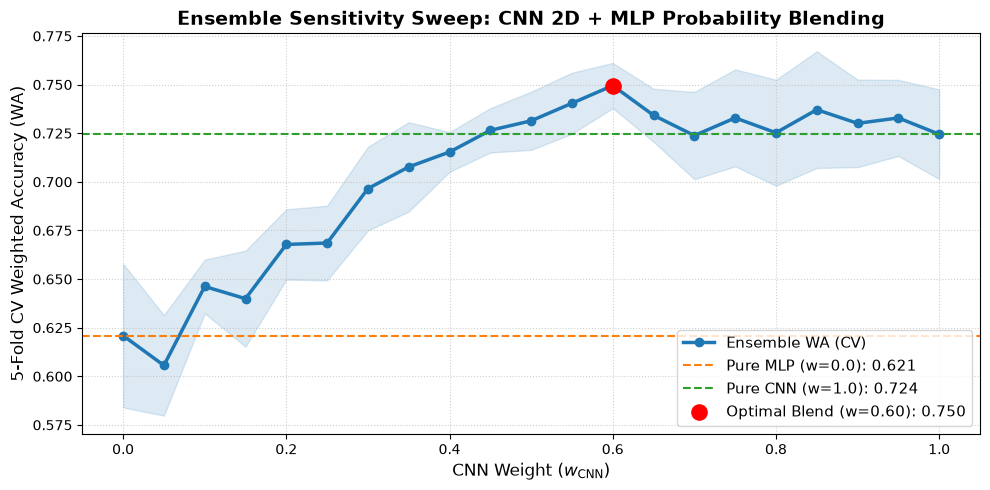

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(sweep_df['w_cnn'], sweep_df['WA (CV)'], marker='o', color='#1f77b4', linewidth=2.5, label='Ensemble WA (CV)')
plt.fill_between(sweep_df['w_cnn'], sweep_df['WA (CV)'] - sweep_df['WA_std'], sweep_df['WA (CV)'] + sweep_df['WA_std'], color='#1f77b4', alpha=0.15)

# Benchmark lines
mlp_wa = sweep_df.loc[sweep_df['w_cnn'] == 0.0, 'WA (CV)'].values[0]
cnn_wa = sweep_df.loc[sweep_df['w_cnn'] == 1.0, 'WA (CV)'].values[0]
best_w = best_row['w_cnn']
best_wa = best_row['WA (CV)']

plt.axhline(mlp_wa, color='#ff7f0e', linestyle='--', label=f'Pure MLP (w=0.0): {mlp_wa:.3f}')
plt.axhline(cnn_wa, color='#2ca02c', linestyle='--', label=f'Pure CNN (w=1.0): {cnn_wa:.3f}')
plt.scatter([best_w], [best_wa], color='red', s=120, zorder=5, label=f'Optimal Blend (w={best_w:.2f}): {best_wa:.3f}')

plt.xlabel('CNN Weight ($w_{\\text{CNN}}$)', fontsize=12)
plt.ylabel('5-Fold CV Weighted Accuracy (WA)', fontsize=12)
plt.title('Ensemble Sensitivity Sweep: CNN 2D + MLP Probability Blending', fontsize=14, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, fontsize=11)
plt.tight_layout()
plt.show()

## 5. Confusion Matrix & Diagnostics of the Optimal Ensemble

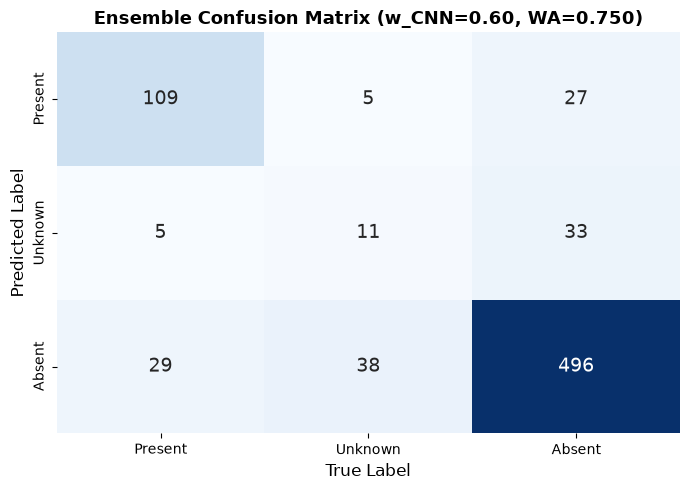

Per-Class Recall:
  - Present: 76.2%
  - Unknown: 20.4%
  - Absent: 89.2%


In [7]:
# Compute predictions with best weight
opt_w = best_row['w_cnn']
best_wa, best_std, best_rep, best_pat, best_preds = eval_blend(opt_w, pat_cnn, pat_mlp)

cm = pd.crosstab(
    best_preds,
    best_pat['murmur'],
    rownames=['Predicted'],
    colnames=['True'],
).reindex(index=CLASSES, columns=CLASSES, fill_value=0)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, annot_kws={'size': 14})
plt.title(f'Ensemble Confusion Matrix (w_CNN={opt_w:.2f}, WA={best_wa:.3f})', fontsize=13, fontweight='bold')
plt.ylabel('Predicted Label', fontsize=12)
plt.xlabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

print("Per-Class Recall:")
for c in CLASSES:
    print(f"  - {c}: {best_rep['recall'][c]:.1%}")

## 6. Grand Comparison Table Across All Project Models

This table unifies all models built throughout the project under the strict patient-level 5-fold CV protocol.

In [8]:
comparison_summary = [
    {
        "Model": "Baseline Cega (Always Present)",
        "Paradigm": "Trivial Rule",
        "Input Data": "None",
        "CV Weighted Accuracy": 0.499,
        "Recall Present": 1.000,
        "Recall Absent": 0.000
    },
    {
        "Model": "Logistic Regression",
        "Paradigm": "Classical ML",
        "Input Data": "123 Summary Feats (Patient level)",
        "CV Weighted Accuracy": 0.574,
        "Recall Present": 0.545,
        "Recall Absent": 0.669
    },
    {
        "Model": "Random Forest",
        "Paradigm": "Classical ML",
        "Input Data": "123 Summary Feats (Patient level)",
        "CV Weighted Accuracy": 0.554,
        "Recall Present": 0.364,
        "Recall Absent": 0.874
    },
    {
        "Model": "MLP (Deep Learning 1)",
        "Paradigm": "Feedforward Neural Net",
        "Input Data": "156 Window Features (Audio)",
        "CV Weighted Accuracy": round(mlp_wa, 3),
        "Recall Present": round(sweep_df.loc[sweep_df['w_cnn'] == 0.0, 'Recall Present'].values[0], 3),
        "Recall Absent": round(sweep_df.loc[sweep_df['w_cnn'] == 0.0, 'Recall Absent'].values[0], 3)
    },
    {
        "Model": "2D CNN (Deep Learning 2)",
        "Paradigm": "Convolutional Neural Net",
        "Input Data": "Log-Mel Spectrograms (64x312)",
        "CV Weighted Accuracy": round(cnn_wa, 3),
        "Recall Present": round(sweep_df.loc[sweep_df['w_cnn'] == 1.0, 'Recall Present'].values[0], 3),
        "Recall Absent": round(sweep_df.loc[sweep_df['w_cnn'] == 1.0, 'Recall Absent'].values[0], 3)
    },
    {
        "Model": f"Ensemble (CNN {int(opt_w*100)}% + MLP {int((1-opt_w)*100)}%)",
        "Paradigm": "Late Probability Blending",
        "Input Data": "Spectrograms + Window Feats",
        "CV Weighted Accuracy": round(best_wa, 3),
        "Recall Present": round(best_rep['recall']['Present'], 3),
        "Recall Absent": round(best_rep['recall']['Absent'], 3)
    }
]

master_df = pd.DataFrame(comparison_summary).set_index("Model")
display(master_df)


,Paradigm,Input Data,CV Weighted Accuracy,Recall Present,Recall Absent
Model,,,,,
Baseline Cega (Always Present),Trivial Rule,None,0.499,1.000,0.000
Logistic Regression,Classical ML,123 Summary Feats (Patient level),0.574,0.545,0.669
Random Forest,Classical ML,123 Summary Feats (Patient level),0.554,0.364,0.874
MLP (Deep Learning 1),Feedforward Neural Net,156 Window Features (Audio),0.621,0.727,0.595
2D CNN (Deep Learning 2),Convolutional Neural Net,Log-Mel Spectrograms (64x312),0.724,0.783,0.806
Ensemble (CNN 60% + MLP 40%),Late Probability Blending,Spectrograms + Window Feats,0.750,0.762,0.892
